In [1]:
import tensorflow as tf
from tensorflow import keras

In [2]:
tf.__version__

'2.22.0-rc0'

In [3]:
keras.__version__

'3.16.0.dev2026101604'

In [4]:
keras.version

<function keras.src.version.version()>

In [5]:
fashion_mnist = keras.datasets.fashion_mnist

In [7]:
(X_train_full, y_train_full), (X_test, y_test) = fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 2us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 8s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [8]:
X_train_full.shape

(60000, 28, 28)

In [9]:
X_train_full.dtype

dtype('uint8')

In [10]:
X_valid, X_train = X_train_full[:5000]/255.0, X_train_full[5000:]/255.0

In [18]:
y_valid, y_train = y_train_full[:5000], y_train_full[5000:]

In [19]:
X_train

array([[[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       ...,

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0.

In [20]:
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

In [21]:
class_names[y_train[0]]

'Coat'

In [23]:
model = keras.models.Sequential()
model.add(keras.layers.Flatten(input_shape=[28, 28]))
model.add(keras.layers.Dense(300, activation='relu'))
model.add(keras.layers.Dense(100, activation='relu'))
model.add(keras.layers.Dense(10, activation='softmax'))

In [24]:
keras.utils.plot_model(model, "my_fashion_mnist_model.png", show_shapes=True)

You must install pydot (`pip install pydot`) for `plot_model` to work.


In [25]:
model.layers

[<Flatten name=flatten_1, built=True>,
 <Dense name=dense_1, built=True>,
 <Dense name=dense_2, built=True>,
 <Dense name=dense_3, built=True>]

In [26]:
hidden1 = model.layers[1]

In [32]:
model.compile(loss='sparse_categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])

In [33]:
history = model.fit(X_train, y_train, epochs = 30, validation_data = (X_valid, y_valid))

Epoch 1/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.7611 - loss: 0.7226 - val_accuracy: 0.8308 - val_loss: 0.5049
Epoch 2/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8284 - loss: 0.4912 - val_accuracy: 0.8494 - val_loss: 0.4450
Epoch 3/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8433 - loss: 0.4457 - val_accuracy: 0.8574 - val_loss: 0.4174
Epoch 4/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8525 - loss: 0.4183 - val_accuracy: 0.8628 - val_loss: 0.3997
Epoch 5/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8592 - loss: 0.3984 - val_accuracy: 0.8678 - val_loss: 0.3862
Epoch 6/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8642 - loss: 0.3822 - val_accuracy: 0.8704 - val_loss: 0.3756
Epoch 7/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8690 - loss: 0.3687 - val_accuracy: 0.8736 - val_loss: 0.3669
Epoch 8/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8729 - loss: 0.3570 - 

In [34]:
import pandas as pd
import matplotlib.pyplot as plt

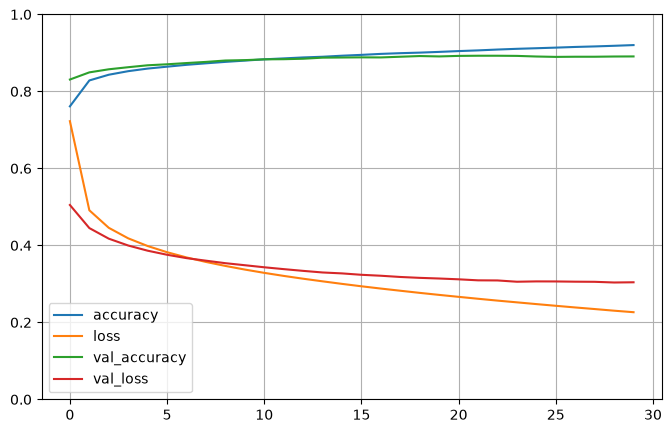

In [35]:
pd.DataFrame(history.history).plot(figsize=(8, 5))
plt.grid(True)
plt.gca().set_ylim(0, 1)
plt.show()

In [36]:
model.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8259 - loss: 78.5806


[78.58060455322266, 0.8259000182151794]

In [38]:
X_new = X_test[:3]
y_proba = model.predict(X_new)
y_proba

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step


array([[0., 0., 0., 0., 0., 0., 0., 0., 0., 1.],
       [0., 0., 1., 0., 0., 0., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0., 0., 0., 0., 0.]], dtype=float32)

In [40]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [41]:
housing = fetch_california_housing()

In [42]:
X_train_full, X_test, y_train_full, y_test = train_test_split(housing.data, housing.target)

In [43]:
X_train, X_valid, y_train, y_valid = train_test_split(X_train_full, y_train_full)

In [44]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_valid = scaler.transform(X_valid)
X_test = scaler.transform(X_test)

In [47]:
X_train[0]

array([-0.53760891,  0.42939958, -0.41071035, -0.12673802,  1.05820973,
       -0.03617896, -1.41810541,  1.25308989])

In [48]:
X_train

array([[-0.53760891,  0.42939958, -0.41071035, ..., -0.03617896,
        -1.41810541,  1.25308989],
       [ 0.79107716, -0.28659758,  0.15370032, ...,  0.00348862,
        -0.64771265,  0.18816487],
       [-0.60015546, -0.36615282, -0.22083759, ..., -0.03499984,
         1.22457522, -1.22012382],
       ...,
       [ 0.08292558,  0.2702891 ,  0.21259498, ..., -0.04621917,
         1.09851095, -0.87676015],
       [ 0.81900251, -1.55948142,  0.61116212, ...,  0.00635096,
        -0.83914357,  1.0838962 ],
       [-1.47497673,  0.58851006, -0.44918351, ...,  0.04860552,
        -1.38075303,  1.2182559 ]], shape=(11610, 8))

In [49]:
model = keras.models.Sequential
([
    keras.layers.Dense(30 , activation = 'relu', input_shape = X_train.shape[1:]),
    keras.layers.Dense(1)
])

c:\Users\Ridhi Jaiin\Desktop\ANN\venv\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


[<Dense name=dense_4, built=False>, <Dense name=dense_5, built=False>]